# Entrenamiento de detección de emociones con CNN + MediaPipe

Importación de paquetes

In [1]:
import os

import cv2
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.utils import to_categorical


Variables del dataset

In [2]:
DATASET_DIR = "dataset_processed"
IMG_SIZE = 64
MODEL_PATH = "model_results/cnn/cnn_emotion.h5"

CLASSES = sorted(os.listdir(os.path.join(DATASET_DIR, "train")))
print("Clases:", CLASSES)


Clases: ['Angry', 'Fear', 'Happy', 'Sad', 'Suprise']


Cargar imágenes y combinarlas con los keypoints geométricos de MediaPipe

In [3]:
def load_split(split_name):
    keypoints_path = os.path.join(DATASET_DIR, f"{split_name}_keypoints.npz")
    kp_data = np.load(keypoints_path, allow_pickle=True)
    kp_features = kp_data["features"].astype("float32")
    kp_labels = kp_data["labels"]
    kp_filenames = kp_data["filenames"]

    split_dir = os.path.join(DATASET_DIR, split_name)

    X_img, y = [], []
    for label, fname in zip(kp_labels, kp_filenames):
        img = cv2.imread(os.path.join(split_dir, label, fname), cv2.IMREAD_GRAYSCALE)
        img = cv2.resize(img, (IMG_SIZE, IMG_SIZE))
        X_img.append(img)
        y.append(CLASSES.index(label))

    X_img = np.array(X_img, dtype="float32") / 255.0
    X_img = X_img.reshape(-1, IMG_SIZE, IMG_SIZE, 1)
    X_geo = kp_features
    y = to_categorical(y, num_classes=len(CLASSES))
    return X_img, X_geo, y


X_train_img, X_train_geo, y_train = load_split("train")
X_test_img, X_test_geo, y_test = load_split("test")

print("Train:", X_train_img.shape, X_train_geo.shape, "Test:", X_test_img.shape, X_test_geo.shape)


Train: (36502, 64, 64, 1) (36502, 9) Test: (9182, 64, 64, 1) (9182, 9)


Data Augmentation Offline

In [4]:
def augment_images(images, rng):
    augmented = np.empty_like(images)
    h, w = images.shape[1], images.shape[2]
    center = (w / 2, h / 2)
    for i in range(images.shape[0]):
        angle = rng.uniform(-8, 8)
        tx = rng.uniform(-0.08, 0.08) * w
        ty = rng.uniform(-0.08, 0.08) * h
        rot_mat = cv2.getRotationMatrix2D(center, angle, 1.0)
        rot_mat[0, 2] += tx
        rot_mat[1, 2] += ty
        img = cv2.warpAffine(
            images[i, :, :, 0], rot_mat, (w, h), borderMode=cv2.BORDER_REFLECT
        )
        brightness = rng.uniform(0.9, 1.1)
        img = np.clip(img * brightness, 0.0, 1.0)
        augmented[i, :, :, 0] = img
    return augmented


y_train_int_full = np.argmax(y_train, axis=1)
X_tr_img, X_val_img, X_tr_geo, X_val_geo, y_tr, y_val = train_test_split(
    X_train_img, X_train_geo, y_train,
    test_size=0.1, stratify=y_train_int_full, random_state=42,
)

rng = np.random.default_rng(42)
X_tr_img_aug = augment_images(X_tr_img, rng)

X_train_img = np.concatenate([X_tr_img, X_tr_img_aug], axis=0)
X_train_geo = np.concatenate([X_tr_geo, X_tr_geo], axis=0)
y_train = np.concatenate([y_tr, y_tr], axis=0)

print("Train tras aumentación offline:", X_train_img.shape, X_train_geo.shape, y_train.shape)
print("Validación (sin aumentar):", X_val_img.shape, X_val_geo.shape, y_val.shape)


Train tras aumentación offline: (65702, 64, 64, 1) (65702, 9) (65702, 5)
Validación (sin aumentar): (3651, 64, 64, 1) (3651, 9) (3651, 5)


Definición de la CNN

In [5]:
image_input = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 1), name="image_input")
x = layers.Conv2D(32, (3, 3), activation="relu", padding="same")(image_input)
x = layers.BatchNormalization()(x)
x = layers.MaxPooling2D((2, 2))(x)
x = layers.Conv2D(64, (3, 3), activation="relu", padding="same")(x)
x = layers.BatchNormalization()(x)
x = layers.MaxPooling2D((2, 2))(x)
x = layers.Conv2D(128, (3, 3), activation="relu", padding="same")(x)
x = layers.BatchNormalization()(x)
x = layers.MaxPooling2D((2, 2))(x)
x = layers.Flatten()(x)
x = layers.Dense(128, activation="relu")(x)
x = layers.Dropout(0.5)(x)

geo_input = layers.Input(shape=(X_train_geo.shape[1],), name="geo_input")
g = layers.Dense(32, activation="relu")(geo_input)

combined = layers.Concatenate()([x, g])
combined = layers.Dense(64, activation="relu")(combined)
output = layers.Dense(len(CLASSES), activation="softmax")(combined)

model = models.Model(inputs=[image_input, geo_input], outputs=output)
model.compile(optimizer=Adam(learning_rate=1e-4), loss="categorical_crossentropy", metrics=["accuracy"])
model.summary()


Model: "model"
__________________________________________________________________________________________________
 Layer (type)                   Output Shape         Param #     Connected to                     
 image_input (InputLayer)       [(None, 64, 64, 1)]  0           []                               
                                                                                                  
 conv2d (Conv2D)                (None, 64, 64, 32)   320         ['image_input[0][0]']            
                                                                                                  
 batch_normalization (BatchNorm  (None, 64, 64, 32)  128         ['conv2d[0][0]']                 
 alization)                                                                                       
                                                                                                  
 max_pooling2d (MaxPooling2D)   (None, 32, 32, 32)   0           ['batch_normalization[0][0]']

Entrenamiento

In [6]:
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True,
)
reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=5,
    min_lr=1e-6,
)

history = model.fit(
    [X_train_img, X_train_geo], y_train,
    validation_data=([X_val_img, X_val_geo], y_val),
    epochs=50,
    batch_size=64,
    callbacks=[early_stopping, reduce_lr],
)

test_loss, test_accuracy = model.evaluate([X_test_img, X_test_geo], y_test)
print("Accuracy en test:", test_accuracy)


Epoch 1/50
1027/1027 [==============================] - 14s 13ms/step - loss: 1.3639 - accuracy: 0.4336 - val_loss: 1.1460 - val_accuracy: 0.5300 - lr: 1.0000e-04
Epoch 2/50
1027/1027 [==============================] - 12s 12ms/step - loss: 1.1416 - accuracy: 0.5347 - val_loss: 0.9708 - val_accuracy: 0.5993 - lr: 1.0000e-04
Epoch 3/50
1027/1027 [==============================] - 13s 13ms/step - loss: 1.0277 - accuracy: 0.5885 - val_loss: 0.9112 - val_accuracy: 0.6376 - lr: 1.0000e-04
Epoch 4/50
1027/1027 [==============================] - 13s 12ms/step - loss: 0.9475 - accuracy: 0.6192 - val_loss: 0.8370 - val_accuracy: 0.6623 - lr: 1.0000e-04
Epoch 5/50
1027/1027 [==============================] - 13s 12ms/step - loss: 0.8849 - accuracy: 0.6459 - val_loss: 0.7756 - val_accuracy: 0.6880 - lr: 1.0000e-04
Epoch 6/50
1027/1027 [==============================] - 13s 12ms/step - loss: 0.8258 - accuracy: 0.6688 - val_loss: 0.7309 - val_accuracy: 0.7132 - lr: 1.0000e-04
Epoch 7/50
1027/1027 [

Guardar el modelo entrenado y generar una gráfica de los resultados

Modelo guardado en model_results/cnn/cnn_emotion.h5


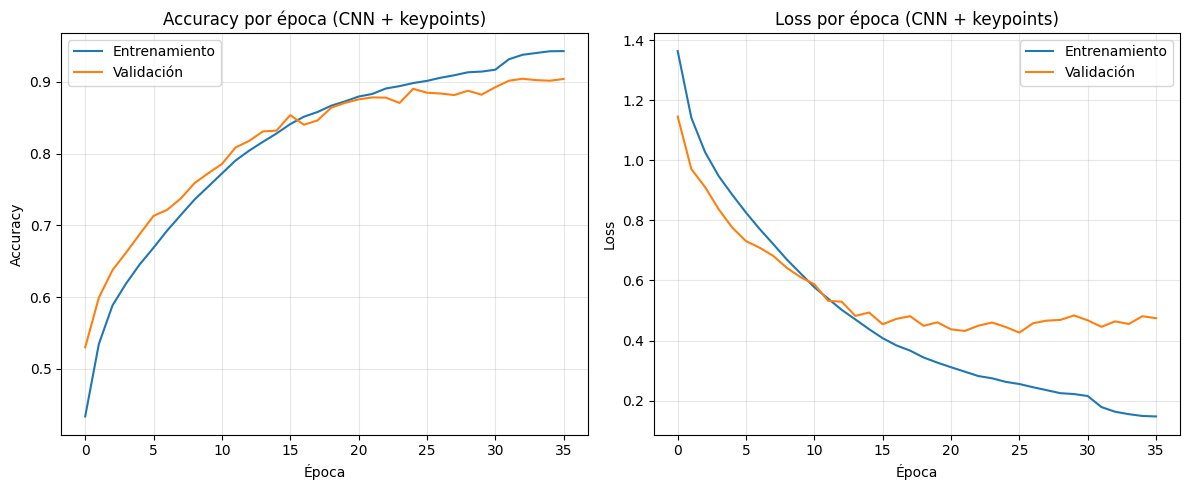

In [7]:
os.makedirs(os.path.dirname(MODEL_PATH), exist_ok=True)
model.save(MODEL_PATH)
print(f"Modelo guardado en {MODEL_PATH}")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].plot(history.history["accuracy"], label="Entrenamiento")
axes[0].plot(history.history["val_accuracy"], label="Validación")
axes[0].set_title("Accuracy por época (CNN + keypoints)")
axes[0].set_xlabel("Época")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(history.history["loss"], label="Entrenamiento")
axes[1].plot(history.history["val_loss"], label="Validación")
axes[1].set_title("Loss por época (CNN + keypoints)")
axes[1].set_xlabel("Época")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(alpha=0.3)

fig.tight_layout()
fig.savefig("model_results/cnn/cnn_training_curves.png", dpi=150)
plt.show()

Resultados por clase

287/287 [==============================] - 1s 4ms/step
              precision    recall  f1-score   support

       Angry       0.87      0.82      0.84      1540
        Fear       0.83      0.80      0.81      1413
       Happy       0.94      0.96      0.95      3105
         Sad       0.84      0.85      0.84      1755
     Suprise       0.92      0.93      0.92      1369

    accuracy                           0.89      9182
   macro avg       0.88      0.87      0.88      9182
weighted avg       0.89      0.89      0.89      9182



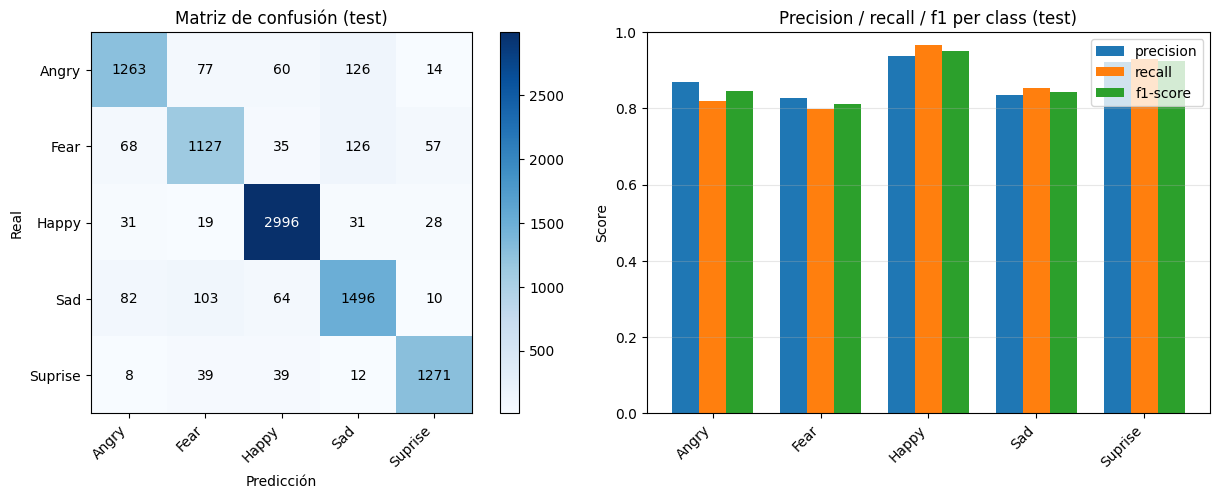

In [8]:
y_pred_idx = np.argmax(model.predict([X_test_img, X_test_geo]), axis=1)
y_true_idx = np.argmax(y_test, axis=1)
y_pred_labels = [CLASSES[i] for i in y_pred_idx]
y_true_labels = [CLASSES[i] for i in y_true_idx]

report = classification_report(
    y_true_labels, y_pred_labels, labels=CLASSES, target_names=CLASSES, output_dict=True
)
print(classification_report(y_true_labels, y_pred_labels, labels=CLASSES, target_names=CLASSES))

cm = confusion_matrix(y_true_labels, y_pred_labels, labels=CLASSES)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

im = axes[0].imshow(cm, cmap="Blues")
axes[0].set_xticks(range(len(CLASSES)))
axes[0].set_xticklabels(CLASSES, rotation=45, ha="right")
axes[0].set_yticks(range(len(CLASSES)))
axes[0].set_yticklabels(CLASSES)
axes[0].set_xlabel("Predicción")
axes[0].set_ylabel("Real")
axes[0].set_title("Matriz de confusión (test)")
threshold = cm.max() / 2
for i in range(len(CLASSES)):
    for j in range(len(CLASSES)):
        color = "white" if cm[i, j] > threshold else "black"
        axes[0].text(j, i, cm[i, j], ha="center", va="center", color=color)
fig.colorbar(im, ax=axes[0])

metrics = ["precision", "recall", "f1-score"]
x = np.arange(len(CLASSES))
width = 0.25
for i, metric in enumerate(metrics):
    values = [report[label][metric] for label in CLASSES]
    axes[1].bar(x + (i - 1) * width, values, width, label=metric)
axes[1].set_xticks(x)
axes[1].set_xticklabels(CLASSES, rotation=45, ha="right")
axes[1].set_ylim(0, 1)
axes[1].set_ylabel("Score")
axes[1].set_title("Precision / recall / f1 per class (test)")
axes[1].legend()
axes[1].grid(alpha=0.3, axis="y")

fig.tight_layout()
fig.savefig("model_results/cnn/cnn_per_class_results.png", dpi=150)
plt.show()
